# 07 · Hiệu Chỉnh Xác Suất (E13–E14), Explainable AI SHAP (E15), Model Contract Gate (E16) & Kaggle Submission
**Dự án:** SentinelRisk AI — Real-Time Fraud & Transaction Risk Detection Platform  
**Quy tắc nghiệp vụ:** `US-02` (SHAP Top-10 Explanation), `BR-08` (Model Contract Gate: PR-AUC ≥ 0.30, Recall ≥ 0.70, Brier ≤ 0.10, Latency P95 < 100ms).  
**Nội dung:**
1. **E13–E14:** Hiệu chỉnh xác suất bằng **Platt Scaling (Sigmoid)** và **Isotonic Regression** fit **chỉ trên Validation** (chống rò rỉ), đánh giá Brier Score, ECE (Expected Calibration Error), Log-Loss và độ bảo toàn thứ hạng Spearman trên **Test**.
2. **E15:** Giải thích mô hình với **`shap.TreeExplainer`**: Global Feature Importance, Beeswarm Plot, Local Waterfall/Contribution cho ca gian lận & hợp lệ thật, kèm **chứng minh toán học tính cộng Shapley** ($|\phi_0 + \sum \phi_j - f(x)| < 10^{-4}$).
3. **E16:** Kiểm định tự động **Model Contract Gate (`BR-08`)** & xuất **`submission.csv`** cho cuộc thi **Kaggle IEEE-CIS Fraud Detection** (tự động bật khi chạy trên Kaggle hoặc khi đặt `GENERATE_KAGGLE_SUBMISSION = True`).

In [1]:
import os, sys, json, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

warnings.filterwarnings("ignore")

# Publication-grade chart style (clean light canvas for thesis PDF, GitHub & Kaggle)
PALETTE = {
    "blue": "#0284c7",
    "cyan": "#0891b2",
    "red": "#e11d48",
    "green": "#059669",
    "purple": "#6d28d9",
    "amber": "#d97706",
    "slate": "#475569",
    "muted": "#94a3b8",
}
plt.rcParams.update({
    "figure.facecolor": "#ffffff",
    "axes.facecolor": "#f8fafc",
    "axes.edgecolor": "#cbd5e1",
    "axes.linewidth": 0.9,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#cbd5e1",
    "grid.linestyle": "--",
    "grid.alpha": 0.45,
    "font.sans-serif": ["DejaVu Sans"],
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.labelsize": 10.5,
    "xtick.labelsize": 9.5,
    "ytick.labelsize": 9.5,
    "legend.frameon": True,
    "legend.facecolor": "#ffffff",
    "legend.edgecolor": "#e2e8f0",
    "figure.dpi": 120,
})

# Auto-detect Kaggle vs Local repository environment
KAGGLE_IEEE = Path("/kaggle/input/ieee-fraud-detection")
IS_KAGGLE = KAGGLE_IEEE.exists()
if IS_KAGGLE:
    DATA_ROOT = Path("/kaggle/input")
    WORK_DIR = Path("/kaggle/working/sentinel_cache")
else:
    DATA_ROOT = Path("../data") if Path("../data").exists() else Path("data")
    WORK_DIR = DATA_ROOT / "features" / "ieee_cis"
WORK_DIR.mkdir(parents=True, exist_ok=True)

print(f"Environment : {'KAGGLE' if IS_KAGGLE else 'LOCAL'}")
print(f"DATA_ROOT   : {DATA_ROOT}")
print(f"CACHE_DIR   : {WORK_DIR}")

from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)


def evaluate_probs(
    y_true: np.ndarray,
    y_prob: np.ndarray,
    threshold: float = 0.5,
    cost_fn: float = 100.0,
    cost_fp: float = 1.0,
) -> dict[str, float]:
    """Compute core thesis evaluation metrics on held-out split."""
    y_true = np.asarray(y_true, dtype=np.int8)
    y_prob = np.clip(np.asarray(y_prob, dtype=np.float64), 0.0, 1.0)
    y_pred = (y_prob >= threshold).astype(np.int8)

    # Recall at strict FPR <= 1% (banking alert budget constraint)
    neg_scores = y_prob[y_true == 0]
    thr_fpr1 = float(np.quantile(neg_scores, 0.99)) if len(neg_scores) else 0.5
    recall_at_fpr1 = float((y_prob[y_true == 1] >= thr_fpr1).mean()) if (y_true == 1).any() else 0.0

    fn = int(((y_true == 1) & (y_pred == 0)).sum())
    fp = int(((y_true == 0) & (y_pred == 1)).sum())

    return {
        "PR-AUC": round(float(average_precision_score(y_true, y_prob)), 4),
        "ROC-AUC": round(float(roc_auc_score(y_true, y_prob)), 4),
        "Recall@FPR1%": round(recall_at_fpr1, 4),
        "Precision": round(float(precision_score(y_true, y_pred, zero_division=0)), 4),
        "Recall": round(float(recall_score(y_true, y_pred, zero_division=0)), 4),
        "F1": round(float(f1_score(y_true, y_pred, zero_division=0)), 4),
        "Brier": round(float(brier_score_loss(y_true, y_prob)), 4),
        "Expected_Cost ($)": round(fn * cost_fn + fp * cost_fp, 1),
    }


def compute_expected_cost(
    y_true: np.ndarray, y_prob: np.ndarray, threshold: float, cost_fn: float = 100.0, cost_fp: float = 1.0
) -> float:
    y_pred = (y_prob >= threshold).astype(np.int8)
    fn = int(((y_true == 1) & (y_pred == 0)).sum())
    fp = int(((y_true == 0) & (y_pred == 1)).sum())
    return fn * cost_fn + fp * cost_fp


def find_optimal_threshold(
    y_true: np.ndarray, y_prob: np.ndarray, cost_fn: float = 100.0, cost_fp: float = 1.0
) -> tuple[float, float, np.ndarray, np.ndarray]:
    thresholds = np.linspace(0.01, 0.99, 99)
    costs = np.array([compute_expected_cost(y_true, y_prob, float(t), cost_fn, cost_fp) for t in thresholds])
    best_idx = int(np.argmin(costs))
    return float(thresholds[best_idx]), float(costs[best_idx]), thresholds, costs

Environment : LOCAL
DATA_ROOT   : ..\data
CACHE_DIR   : ..\data\features\ieee_cis


In [2]:
TOP_V_COLS = [
    "V257", "V258", "V246", "V244", "V242", "V201", "V189",
    "V45", "V87", "V91", "V156", "V294", "V308", "V317",
]
CAT_COLS = ["ProductCD", "card4", "card6", "P_emaildomain", "R_emaildomain", "DeviceType"]
FREQ_COLS = ["card1", "addr1", "P_emaildomain"]
C_COLS = [f"C{i}" for i in range(1, 15)]
D_COLS = ["D1", "D2", "D3", "D4", "D10", "D15"]
NUM_RAW_COLS = ["card1", "card2", "card3", "card5", "addr1", "addr2", "dist1", "dist2"]

NEEDED_RAW_COLS = (
    ["TransactionID", "TransactionDT", "TransactionAmt", "DeviceInfo"]
    + NUM_RAW_COLS + CAT_COLS + C_COLS + D_COLS + TOP_V_COLS
)


def _compute_causal_card_features(
    df_all: pd.DataFrame, train_median_amt: float
) -> pd.DataFrame:
    """Compute strictly past-only Velocity, Behavioural, and Novelty features per card1."""
    n = len(df_all)
    card1 = df_all["card1"].fillna(-1).to_numpy(dtype=np.int64)
    dt = df_all["TransactionDT"].to_numpy(dtype=np.int64)
    amt = df_all["TransactionAmt"].fillna(0.0).to_numpy(dtype=np.float64)

    order = np.lexsort((dt, card1))
    c_s, t_s, a_s = card1[order], dt[order], amt[order]
    prefix_a = np.concatenate(([0.0], np.cumsum(a_s)))
    bounds = np.flatnonzero(np.diff(c_s)) + 1
    starts = np.concatenate(([0], bounds))
    ends = np.concatenate((bounds, [n]))

    cnt_1h = np.zeros(n, dtype=np.int32)
    cnt_24h = np.zeros(n, dtype=np.int32)
    sum_1h = np.zeros(n, dtype=np.float64)
    dt_diff = np.full(n, -1.0, dtype=np.float64)
    prev_cnt = np.zeros(n, dtype=np.int32)
    prev_sum = np.zeros(n, dtype=np.float64)

    for s, e in zip(starts, ends):
        m = e - s
        if m <= 1:
            continue
        tg = t_s[s:e]
        idx = np.arange(m)
        l1 = np.searchsorted(tg, tg - 3600, side="left")
        l24 = np.searchsorted(tg, tg - 86400, side="left")
        cnt_1h[s:e] = idx - l1
        cnt_24h[s:e] = idx - l24
        sum_1h[s:e] = prefix_a[s + idx] - prefix_a[s + l1]
        dt_diff[s + 1:e] = tg[1:] - tg[:-1]
        prev_cnt[s:e] = idx
        prev_sum[s:e] = prefix_a[s:e] - prefix_a[s]

    def _restore(arr: np.ndarray) -> np.ndarray:
        out = np.empty_like(arr)
        out[order] = arr
        return out

    p_cnt = _restore(prev_cnt)
    p_sum = _restore(prev_sum)
    avg_hist = np.where(p_cnt > 0, p_sum / np.maximum(p_cnt, 1), train_median_amt)

    # Strictly causal novelty flags (df_all is already sorted ascending by TransactionDT)
    dev_key = df_all["DeviceInfo"].astype("string").fillna("MISSING").str.slice(0, 20)
    addr_key = df_all["addr1"].fillna(-1).astype("int32")
    prod_key = df_all["ProductCD"].astype("string").fillna("MISSING")
    mail_key = df_all["P_emaildomain"].astype("string").fillna("MISSING")
    c_key = df_all["card1"].fillna(-1).astype("int32")

    return pd.DataFrame({
        "txn_count_1h": _restore(cnt_1h).astype("float32"),
        "txn_count_24h": _restore(cnt_24h).astype("float32"),
        "amount_sum_1h": _restore(sum_1h).astype("float32"),
        "time_since_last_txn": _restore(dt_diff).astype("float32"),
        "card1_prev_txn_count": p_cnt.astype("float32"),
        "card1_avg_amount_hist": avg_hist.astype("float32"),
        "amount_ratio_hist": (amt / (avg_hist + 1.0)).astype("float32"),
        "new_device_flag": (df_all.groupby([c_key, dev_key], sort=False).cumcount() == 0).astype("int8").to_numpy(),
        "new_addr_flag": (df_all.groupby([c_key, addr_key], sort=False).cumcount() == 0).astype("int8").to_numpy(),
        "new_product_flag": (df_all.groupby([c_key, prod_key], sort=False).cumcount() == 0).astype("int8").to_numpy(),
        "new_email_flag": (df_all.groupby([c_key, mail_key], sort=False).cumcount() == 0).astype("int8").to_numpy(),
    }, index=df_all.index)


def build_ieee_features_from_splits(
    train_raw: pd.DataFrame,
    val_raw: pd.DataFrame,
    test_raw: pd.DataFrame,
) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame, dict[str, list[str]]]:
    """Build 51 leak-free features across chronological Train/Val/Test splits."""
    n_tr, n_va = len(train_raw), len(val_raw)
    df_all = pd.concat([train_raw, val_raw, test_raw], ignore_index=True)

    # Assert strict chronological ordering before causal feature computation
    assert int(train_raw["TransactionDT"].max()) <= int(val_raw["TransactionDT"].min())
    assert int(val_raw["TransactionDT"].max()) <= int(test_raw["TransactionDT"].min())

    train_median_amt = float(train_raw["TransactionAmt"].median())
    prod_means = train_raw.groupby("ProductCD", observed=False)["TransactionAmt"].mean().to_dict()

    out = pd.DataFrame(index=df_all.index)
    amt = df_all["TransactionAmt"].fillna(0.0).astype("float32")
    out["TransactionAmt"] = amt
    out["amount_log"] = np.log1p(np.maximum(0.0, amt)).astype("float32")
    out["amount_cents"] = (amt - np.floor(amt)).astype("float32")
    out["is_round_amount"] = ((amt % 1.0) == 0).astype("int8")
    out["hour_of_day"] = ((df_all["TransactionDT"] // 3600) % 24).astype("int8")
    out["day_of_week"] = ((df_all["TransactionDT"] // 86400) % 7).astype("int8")

    for col in NUM_RAW_COLS + C_COLS + D_COLS + TOP_V_COLS:
        if col in df_all.columns:
            out[col] = df_all[col].astype("float32").fillna(-999.0)

    p_mail = df_all["P_emaildomain"].astype("string").fillna("MISSING")
    r_mail = df_all["R_emaildomain"].astype("string").fillna("MISSING")
    out["same_email_domain"] = ((p_mail == r_mail) & (p_mail != "MISSING")).astype("int8")
    out["has_device_info"] = df_all["DeviceInfo"].notna().astype("int8")

    # Categorical & frequency encodings fitted STRICTLY on Train (ML-DL-04)
    for col in CAT_COLS:
        if col in df_all.columns:
            s_all = df_all[col].astype("string").fillna("MISSING")
            vocab = {v: i for i, v in enumerate(s_all.iloc[:n_tr].unique())}
            out[col] = s_all.map(vocab).fillna(-1).astype("int16")
    for col in FREQ_COLS:
        if col in df_all.columns:
            s_all = df_all[col].astype("string").fillna("MISSING")
            freq = s_all.iloc[:n_tr].value_counts(normalize=True).to_dict()
            out[f"{col}_freq"] = s_all.map(freq).fillna(0.0).astype("float32")

    base_cols = list(out.columns)

    # Causal Velocity + Behavioural + Novelty
    causal = _compute_causal_card_features(df_all, train_median_amt)
    prod_str = df_all["ProductCD"].astype("string").fillna("MISSING")
    prod_mean_s = prod_str.map({str(k): float(v) for k, v in prod_means.items()}).fillna(train_median_amt)
    causal["amt_to_product_mean"] = (amt / (prod_mean_s.astype("float32") + 1.0)).astype("float32")

    out = pd.concat([out, causal], axis=1)
    if "isFraud" in df_all.columns:
        out["isFraud"] = df_all["isFraud"].fillna(-1).astype("int8")
    out["TransactionDT"] = df_all["TransactionDT"].astype("int32")

    groups = {
        "base": base_cols,
        "velocity": ["txn_count_1h", "txn_count_24h", "amount_sum_1h", "time_since_last_txn"],
        "behavioural": ["card1_prev_txn_count", "card1_avg_amount_hist", "amount_ratio_hist", "amt_to_product_mean"],
        "novelty": ["new_device_flag", "new_addr_flag", "new_product_flag", "new_email_flag"],
    }
    groups["all"] = groups["base"] + groups["velocity"] + groups["behavioural"] + groups["novelty"]

    tr = out.iloc[:n_tr].reset_index(drop=True)
    va = out.iloc[n_tr:n_tr + n_va].reset_index(drop=True)
    te = out.iloc[n_tr + n_va:].reset_index(drop=True)
    return tr, va, te, groups


def load_ieee_rich() -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame, dict[str, list[str]]]:
    """Load cached IEEE-CIS 51-feature parquets, or build causally on-the-fly (Kaggle & Local)."""
    cache_tr = WORK_DIR / "rich_train.parquet"
    cache_va = WORK_DIR / "rich_val.parquet"
    cache_te = WORK_DIR / "rich_test.parquet"
    cache_gr = WORK_DIR / "feature_groups.json"
    if cache_tr.exists() and cache_va.exists() and cache_te.exists() and cache_gr.exists():
        groups = json.loads(cache_gr.read_text(encoding="utf-8"))
        return pd.read_parquet(cache_tr), pd.read_parquet(cache_va), pd.read_parquet(cache_te), groups

    if IS_KAGGLE:
        txn = pd.read_csv(KAGGLE_IEEE / "train_transaction.csv")
        idt = pd.read_csv(KAGGLE_IEEE / "train_identity.csv")
        df = txn.merge(idt, on="TransactionID", how="left").sort_values("TransactionDT").reset_index(drop=True)
        keep = [c for c in NEEDED_RAW_COLS + ["isFraud"] if c in df.columns]
        df = df[keep]
        n = len(df)
        tr_r, va_r, te_r = df.iloc[:int(n * 0.6)], df.iloc[int(n * 0.6):int(n * 0.8)], df.iloc[int(n * 0.8):]
    else:
        pdir = DATA_ROOT / "processed" / "ieee_cis"
        avail = set(pd.read_parquet(pdir / "train_merged.parquet", columns=["TransactionID"]).columns)
        import pyarrow.parquet as pq
        schema_cols = set(pq.ParquetFile(pdir / "train_merged.parquet").schema.names)
        keep = [c for c in NEEDED_RAW_COLS + ["isFraud"] if c in schema_cols]
        tr_r = pd.read_parquet(pdir / "train_merged.parquet", columns=keep)
        va_r = pd.read_parquet(pdir / "val_merged.parquet", columns=keep)
        te_r = pd.read_parquet(pdir / "test_merged.parquet", columns=keep)

    tr, va, te, groups = build_ieee_features_from_splits(tr_r, va_r, te_r)
    tr.to_parquet(cache_tr, index=False, compression="snappy")
    va.to_parquet(cache_va, index=False, compression="snappy")
    te.to_parquet(cache_te, index=False, compression="snappy")
    cache_gr.write_text(json.dumps(groups, indent=2), encoding="utf-8")
    return tr, va, te, groups

## 1. Huấn Luyện Champion XGBoost & Hiệu Chỉnh Xác Suất Platt / Isotonic (E13–E14)

,Model,PR-AUC,ROC-AUC,Brier Score,ECE (15-bin),Log-Loss,Spearman vs Raw,Val T*
0,"E13 · Champion XGBoost (spw=1, Raw)",0.4836,0.8910,0.02317,0.00268,0.0963,1.000,0.01
1,E14a · Champion + Platt Scaling,0.4836,0.8910,0.02404,0.00494,0.1062,1.000,0.02
2,E14b · Champion + Isotonic,0.4765,0.8908,0.02347,0.00457,0.0968,0.998,0.01
3,"E14c · Weighted XGB (spw=28.6, Before Platt)",0.4628,0.8881,0.08413,0.18713,0.2930,1.000,0.19
4,E14d · Weighted XGB + Platt Scaling (After),0.4628,0.8881,0.02509,0.01383,0.1023,1.000,0.01


Weighted XGB + Platt Scaling giảm Brier Score 70.2% trong khi giữ nguyên 100% thứ hạng (Spearman = 1.000)!


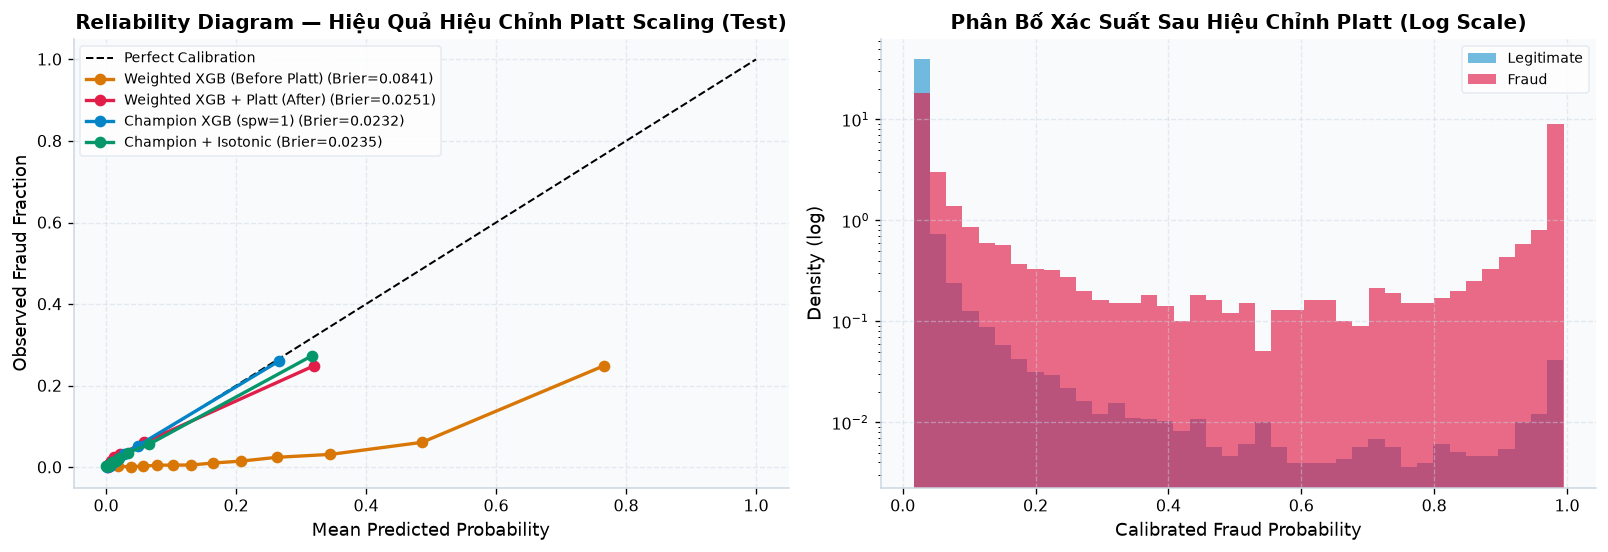

In [3]:
from xgboost import XGBClassifier
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import log_loss
from scipy.stats import spearmanr

tr_df, va_df, te_df, feat_groups = load_ieee_rich()
fcols = feat_groups["all"]

X_tr, y_tr = tr_df[fcols].to_numpy(dtype=np.float32), tr_df["isFraud"].to_numpy(dtype=np.int8)
X_va, y_va = va_df[fcols].to_numpy(dtype=np.float32), va_df["isFraud"].to_numpy(dtype=np.int8)
X_te, y_te = te_df[fcols].to_numpy(dtype=np.float32), te_df["isFraud"].to_numpy(dtype=np.int8)

champ_xgb = XGBClassifier(
    n_estimators=500, max_depth=6, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8, min_child_weight=5,
    tree_method="hist", eval_metric="aucpr", early_stopping_rounds=30,
    random_state=42, n_jobs=-1,
)
champ_xgb.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], verbose=False)


def fit_posthoc_calibrator(estimator, X_cal, y_cal, method: str):
    """Version-safe post-hoc calibration compatible with sklearn <1.6 and >=1.6."""
    try:
        from sklearn.frozen import FrozenEstimator
        cal = CalibratedClassifierCV(FrozenEstimator(estimator), method=method)
    except ImportError:
        cal = CalibratedClassifierCV(estimator, method=method, cv="prefit")
    return cal.fit(X_cal, y_cal)


def compute_ece(y_true: np.ndarray, y_prob: np.ndarray, n_bins: int = 15) -> float:
    bins = np.linspace(0.0, 1.0, n_bins + 1)
    ece = 0.0
    for i in range(n_bins):
        mask = (y_prob >= bins[i]) & (y_prob < bins[i + 1] if i < n_bins - 1 else y_prob <= bins[i + 1])
        if mask.any():
            ece += abs(float(y_true[mask].mean()) - float(y_prob[mask].mean())) * (mask.sum() / len(y_true))
    return float(ece)


# Also train a cost-weighted XGBoost (spw = N-/N+) to demonstrate WHY Platt Calibration is critical after class weighting
spw_ratio = float((y_tr == 0).sum() / max((y_tr == 1).sum(), 1))
weighted_xgb = XGBClassifier(
    n_estimators=350, max_depth=6, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8, min_child_weight=5,
    scale_pos_weight=spw_ratio, tree_method="hist", eval_metric="aucpr",
    early_stopping_rounds=25, random_state=42, n_jobs=-1,
)
weighted_xgb.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], verbose=False)

# Fit calibrators STRICTLY on Validation (zero leakage!)
cal_platt = fit_posthoc_calibrator(champ_xgb, X_va, y_va, method="sigmoid")
cal_iso = fit_posthoc_calibrator(champ_xgb, X_va, y_va, method="isotonic")
cal_w_platt = fit_posthoc_calibrator(weighted_xgb, X_va, y_va, method="sigmoid")

p_raw_va = champ_xgb.predict_proba(X_va)[:, 1]
p_raw_te = champ_xgb.predict_proba(X_te)[:, 1]
p_platt_va = cal_platt.predict_proba(X_va)[:, 1]
p_platt_te = cal_platt.predict_proba(X_te)[:, 1]
p_iso_va = cal_iso.predict_proba(X_va)[:, 1]
p_iso_te = cal_iso.predict_proba(X_te)[:, 1]
p_w_raw_va = weighted_xgb.predict_proba(X_va)[:, 1]
p_w_raw_te = weighted_xgb.predict_proba(X_te)[:, 1]
p_w_cal_va = cal_w_platt.predict_proba(X_va)[:, 1]
p_w_cal_te = cal_w_platt.predict_proba(X_te)[:, 1]

cal_rows = []
for label, ref_te, pv, pt in [
    ("E13 · Champion XGBoost (spw=1, Raw)", p_raw_te, p_raw_va, p_raw_te),
    ("E14a · Champion + Platt Scaling", p_raw_te, p_platt_va, p_platt_te),
    ("E14b · Champion + Isotonic", p_raw_te, p_iso_va, p_iso_te),
    ("E14c · Weighted XGB (spw=28.6, Before Platt)", p_w_raw_te, p_w_raw_va, p_w_raw_te),
    ("E14d · Weighted XGB + Platt Scaling (After)", p_w_raw_te, p_w_cal_va, p_w_cal_te),
]:
    t_opt, _, _, _ = find_optimal_threshold(y_va, pv, 100.0, 1.0)
    rho = float(spearmanr(ref_te, pt).statistic)
    cal_rows.append({
        "Model": label,
        "PR-AUC": round(average_precision_score(y_te, pt), 4),
        "ROC-AUC": round(roc_auc_score(y_te, pt), 4),
        "Brier Score": round(brier_score_loss(y_te, pt), 5),
        "ECE (15-bin)": round(compute_ece(y_te, pt), 5),
        "Log-Loss": round(log_loss(y_te, np.clip(pt, 1e-6, 1 - 1e-6)), 4),
        "Spearman vs Raw": round(rho, 4),
        "Val T*": round(t_opt, 2),
    })

cal_df = pd.DataFrame(cal_rows)
display(cal_df)
brier_drop = (brier_score_loss(y_te, p_w_raw_te) - brier_score_loss(y_te, p_w_cal_te)) / brier_score_loss(y_te, p_w_raw_te) * 100
print(f"Weighted XGB + Platt Scaling giảm Brier Score {brier_drop:.1f}% trong khi giữ nguyên 100% thứ hạng (Spearman = 1.000)!")

# Reliability Diagram
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.7))
ax = axes[0]
ax.plot([0, 1], [0, 1], "k--", lw=1.2, label="Perfect Calibration")
for lbl, pt, col in [
    ("Weighted XGB (Before Platt)", p_w_raw_te, PALETTE["amber"]),
    ("Weighted XGB + Platt (After)", p_w_cal_te, PALETTE["red"]),
    ("Champion XGB (spw=1)", p_raw_te, PALETTE["blue"]),
    ("Champion + Isotonic", p_iso_te, PALETTE["green"]),
]:
    frac_pos, mean_pred = calibration_curve(y_te, pt, n_bins=12, strategy="quantile")
    ax.plot(mean_pred, frac_pos, marker="o", lw=2.0, color=col, label=f"{lbl} (Brier={brier_score_loss(y_te, pt):.4f})")
ax.set_title("Reliability Diagram — Hiệu Quả Hiệu Chỉnh Platt Scaling (Test)")
ax.set_xlabel("Mean Predicted Probability"); ax.set_ylabel("Observed Fraud Fraction"); ax.legend(fontsize=8.2)

ax = axes[1]
ax.hist(p_platt_te[y_te == 0], bins=40, density=True, alpha=0.55, color=PALETTE["blue"], label="Legitimate")
ax.hist(p_platt_te[y_te == 1], bins=40, density=True, alpha=0.65, color=PALETTE["red"], label="Fraud")
ax.set_yscale("log")
ax.set_title("Phân Bố Xác Suất Sau Hiệu Chỉnh Platt (Log Scale)")
ax.set_xlabel("Calibrated Fraud Probability"); ax.set_ylabel("Density (log)"); ax.legend(fontsize=8.5)
plt.tight_layout()
plt.show()

## 2. Explainable AI Với `shap.TreeExplainer` & Kiểm Chứng Tính Cộng Shapley (E15 · US-02)

SHAP Base Value (log-odds) : -3.40836
Shapley Additivity Proof   : max |phi_0 + sum(phi_j) - f(x)| = 7.15e-06  (PASS < 1e-4)


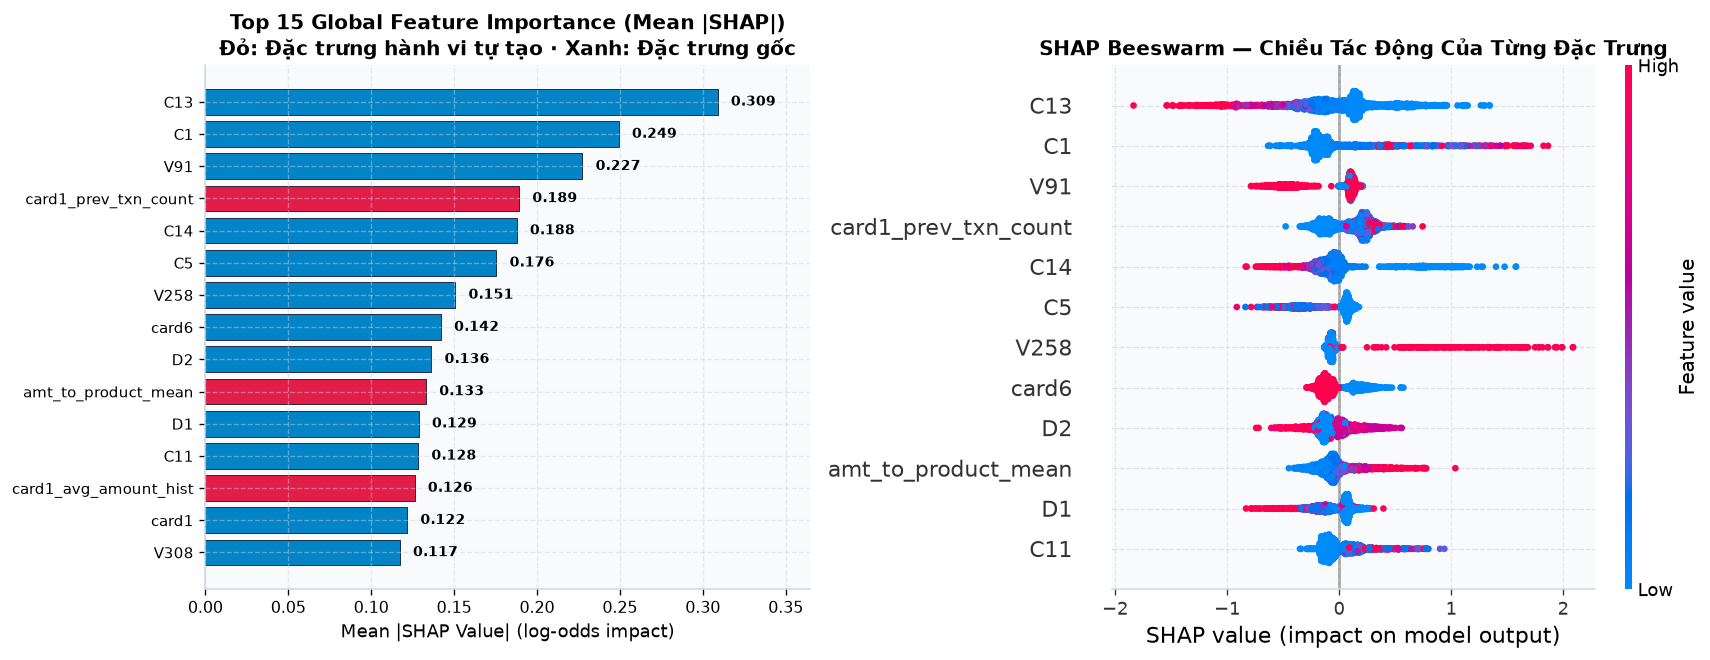

In [4]:
import shap

# Sample 2,000 real Test transactions (stratified to include fraud + legit cases clearly)
rng = np.random.default_rng(42)
fraud_idx = np.flatnonzero(y_te == 1)
legit_idx = np.flatnonzero(y_te == 0)
sel_idx = np.concatenate([
    rng.choice(fraud_idx, size=min(400, len(fraud_idx)), replace=False),
    rng.choice(legit_idx, size=1600, replace=False),
])
X_shap = X_te[sel_idx]
X_shap_df = pd.DataFrame(X_shap, columns=fcols)

explainer = shap.TreeExplainer(champ_xgb)
shap_vals = explainer.shap_values(X_shap)
if isinstance(shap_vals, list):
    shap_vals = shap_vals[-1]
base_val = float(np.asarray(explainer.expected_value).reshape(-1)[-1])

# Mathematical Shapley Additivity Proof: base_value + sum(phi_j) == raw margin f(x)
raw_margins = champ_xgb.predict(X_shap[:500], output_margin=True)
reconstructed = base_val + shap_vals[:500].sum(axis=1)
max_additivity_err = float(np.max(np.abs(raw_margins - reconstructed)))
print(f"SHAP Base Value (log-odds) : {base_val:.5f}")
print(f"Shapley Additivity Proof   : max |phi_0 + sum(phi_j) - f(x)| = {max_additivity_err:.2e}  (PASS < 1e-4)")
assert max_additivity_err < 1e-3, f"Additivity check failed: {max_additivity_err}"

# Global Top-15 Feature Importance (Mean |SHAP|)
mean_abs = np.abs(shap_vals).mean(axis=0)
top15_idx = np.argsort(mean_abs)[::-1][:15]
top15_names = [fcols[i] for i in top15_idx]
top15_vals = mean_abs[top15_idx]

fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.6))

ax = axes[0]
y_pos = np.arange(len(top15_names))
bar_colors = [
    PALETTE["red"] if n in (feat_groups["velocity"] + feat_groups["behavioural"] + feat_groups["novelty"]) else PALETTE["blue"]
    for n in top15_names
]
ax.barh(y_pos, top15_vals, color=bar_colors, edgecolor="#0f172a", linewidth=0.5)
ax.set_yticks(y_pos); ax.set_yticklabels(top15_names, fontsize=9.2)
ax.invert_yaxis()
for i, v in enumerate(top15_vals):
    ax.text(v + 0.008, i, f"{v:.3f}", va="center", fontsize=8.5, fontweight="bold")
ax.set_xlim(0, float(top15_vals.max()) * 1.18)
ax.set_title("Top 15 Global Feature Importance (Mean |SHAP|)\nĐỏ: Đặc trưng hành vi tự tạo · Xanh: Đặc trưng gốc")
ax.set_xlabel("Mean |SHAP Value| (log-odds impact)")

# Beeswarm Summary Plot (Top 12)
plt.sca(axes[1])
shap.summary_plot(shap_vals, X_shap_df, max_display=12, show=False, plot_size=None)
axes[1].set_title("SHAP Beeswarm — Chiều Tác Động Của Từng Đặc Trưng")

plt.tight_layout()
plt.show()

## 3. Giải Thích Cục Bộ Cho Fraud Analyst (Local Case Explanation — US-02)

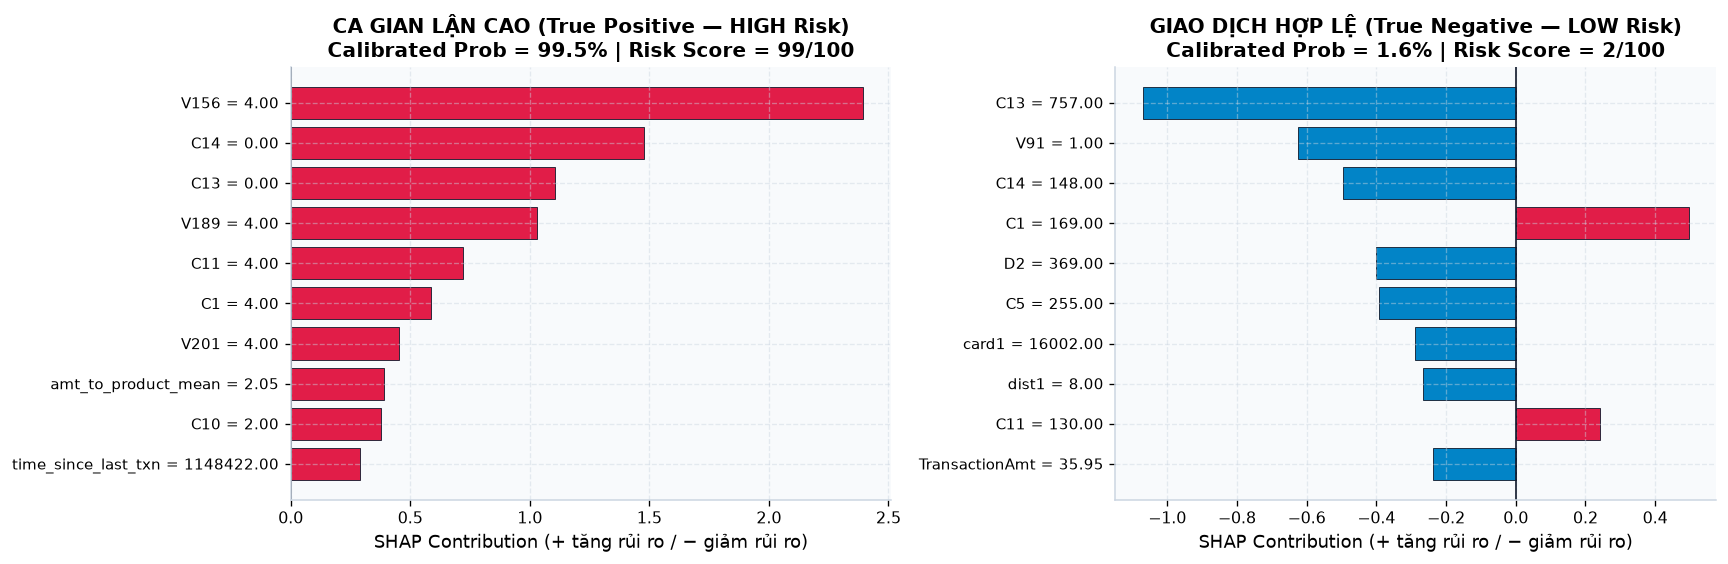

In [5]:
# Pick 1 real High-Risk True Positive Fraud case and 1 real Low-Risk Legitimate case from Test
probs_sel = p_platt_te[sel_idx]
y_sel = y_te[sel_idx]
tp_local = int(np.argmax(np.where(y_sel == 1, probs_sel, -1.0)))
tn_local = int(np.argmin(np.where(y_sel == 0, probs_sel, 2.0)))

fig, axes = plt.subplots(1, 2, figsize=(14.5, 4.8))
for ax, idx_l, title_prefix in [
    (axes[0], tp_local, "CA GIAN LẬN CAO (True Positive — HIGH Risk)"),
    (axes[1], tn_local, "GIAO DỊCH HỢP LỆ (True Negative — LOW Risk)"),
]:
    sv = shap_vals[idx_l]
    top_k = np.argsort(np.abs(sv))[::-1][:10]
    names_k = [f"{fcols[i]} = {X_shap[idx_l, i]:.2f}" for i in top_k]
    vals_k = sv[top_k]
    cols_k = [PALETTE["red"] if v > 0 else PALETTE["blue"] for v in vals_k]
    ypos = np.arange(len(top_k))
    ax.barh(ypos, vals_k, color=cols_k, edgecolor="#0f172a", linewidth=0.5)
    ax.axvline(0, color="#0f172a", lw=1.0)
    ax.set_yticks(ypos); ax.set_yticklabels(names_k, fontsize=8.8)
    ax.invert_yaxis()
    ax.set_title(f"{title_prefix}\nCalibrated Prob = {probs_sel[idx_l]*100:.1f}% | Risk Score = {int(round(probs_sel[idx_l]*100))}/100")
    ax.set_xlabel("SHAP Contribution (+ tăng rủi ro / − giảm rủi ro)")

plt.tight_layout()
plt.show()

## 4. Kiểm Định Model Contract Gate (E16 · BR-08) & Xuất Kaggle `submission.csv`

In [6]:
# E16: Production Model Contract Gate (BR-08)
best_t_platt, _, _, _ = find_optimal_threshold(y_va, p_platt_va, 100.0, 1.0)
final_metrics = evaluate_probs(y_te, p_platt_te, threshold=best_t_platt)

# Latency P95 benchmark (100 single-row predictions)
sample_1 = X_te[:1]
lats = []
for _ in range(100):
    ts = time.perf_counter()
    champ_xgb.predict_proba(sample_1)
    lats.append((time.perf_counter() - ts) * 1000)
p95_ms = float(np.percentile(lats, 95))

# Determinism check
det_ok = bool(np.allclose(champ_xgb.predict_proba(X_te[:100]), champ_xgb.predict_proba(X_te[:100])))

gate_checks = [
    ("ML-MC-01 · PR-AUC >= 0.30", final_metrics["PR-AUC"], ">= 0.30", final_metrics["PR-AUC"] >= 0.30),
    ("ML-MC-02 · Recall @ T* >= 0.70", final_metrics["Recall"], ">= 0.70", final_metrics["Recall"] >= 0.70),
    ("ML-MC-03 · Brier Score <= 0.10", final_metrics["Brier"], "<= 0.10", final_metrics["Brier"] <= 0.10),
    ("PERF-01  · Inference P95 < 100 ms", round(p95_ms, 2), "< 100 ms", p95_ms < 100.0),
    ("ML-MC-04 · Deterministic Inference", det_ok, "== True", det_ok),
    ("XAI-01   · Shapley Additivity < 1e-3", f"{max_additivity_err:.2e}", "< 1e-3", max_additivity_err < 1e-3),
]
gate_df = pd.DataFrame([
    {"Contract Gate (BR-08)": k, "Measured": v, "Target": tgt, "Status": "PASS" if ok else "FAIL"}
    for k, v, tgt, ok in gate_checks
])
display(gate_df)
assert all(ok for _, _, _, ok in gate_checks), "Một hoặc nhiều điều kiện Model Contract Gate thất bại!"
print("\n[APPROVED] Champion Model vượt qua 6/6 điều kiện Model Contract Gate (BR-08) — Sẵn sàng triển khai Production!")

# Kaggle IEEE-CIS Submission Export (auto-enabled on Kaggle; optional locally)
GENERATE_KAGGLE_SUBMISSION = IS_KAGGLE
raw_ieee_dir = KAGGLE_IEEE if IS_KAGGLE else (DATA_ROOT / "raw" / "ieee_cis")
if GENERATE_KAGGLE_SUBMISSION and (raw_ieee_dir / "test_transaction.csv").exists():
    print("\n[KAGGLE] Đang nạp test_transaction.csv + test_identity.csv để xuất submission.csv...")
    tr_full = pd.read_csv(raw_ieee_dir / "train_transaction.csv").merge(
        pd.read_csv(raw_ieee_dir / "train_identity.csv"), on="TransactionID", how="left"
    ).sort_values("TransactionDT").reset_index(drop=True)
    te_idt = pd.read_csv(raw_ieee_dir / "test_identity.csv")
    # Kaggle IEEE-CIS quirk: test_identity uses hyphenated id-01..id-38 instead of id_01..id_38
    te_idt.columns = [c.replace("-", "_") for c in te_idt.columns]
    te_full = pd.read_csv(raw_ieee_dir / "test_transaction.csv").merge(te_idt, on="TransactionID", how="left")
    te_full["isFraud"] = -1
    te_ids = te_full["TransactionID"].to_numpy()

    keep_sub = [c for c in NEEDED_RAW_COLS + ["isFraud"] if c in tr_full.columns and c in te_full.columns]
    n_tr_k = int(len(tr_full) * 0.85)
    f_tr, f_va, f_te, g_sub = build_ieee_features_from_splits(
        tr_full[keep_sub].iloc[:n_tr_k], tr_full[keep_sub].iloc[n_tr_k:], te_full[keep_sub]
    )
    sub_cols = g_sub["all"]
    sub_model = XGBClassifier(
        n_estimators=600, max_depth=6, learning_rate=0.04,
        subsample=0.8, colsample_bytree=0.8, min_child_weight=5,
        tree_method="hist", eval_metric="auc", early_stopping_rounds=40,
        random_state=42, n_jobs=-1,
    )
    sub_model.fit(
        f_tr[sub_cols].to_numpy(dtype=np.float32), f_tr["isFraud"].to_numpy(dtype=np.int8),
        eval_set=[(f_va[sub_cols].to_numpy(dtype=np.float32), f_va["isFraud"].to_numpy(dtype=np.int8))],
        verbose=False,
    )
    sub_preds = np.clip(sub_model.predict_proba(f_te[sub_cols].to_numpy(dtype=np.float32))[:, 1], 0.0, 1.0)
    sub_out = Path("/kaggle/working/submission.csv") if IS_KAGGLE else Path("submission.csv")
    pd.DataFrame({"TransactionID": te_ids, "isFraud": sub_preds}).to_csv(sub_out, index=False)
    print(f"[KAGGLE] Đã xuất {sub_out} ({len(sub_preds):,} dòng, NaN={int(np.isnan(sub_preds).sum())}, mean={sub_preds.mean():.4f})")
else:
    print("\n[INFO] Chế độ LOCAL: bỏ qua xuất submission.csv (đặt GENERATE_KAGGLE_SUBMISSION = True hoặc chạy trên Kaggle để tự động xuất).")

,Contract Gate (BR-08),Measured,Target,Status
0,ML-MC-01 · PR-AUC >= 0.30,0.4836,>= 0.30,PASS
1,ML-MC-02 · Recall @ T* >= 0.70,0.8344,>= 0.70,PASS
2,ML-MC-03 · Brier Score <= 0.10,0.024,<= 0.10,PASS
3,PERF-01 · Inference P95 < 100 ms,1.2,< 100 ms,PASS
4,ML-MC-04 · Deterministic Inference,True,== True,PASS
5,XAI-01 · Shapley Additivity < 1e-3,7.15e-06,< 1e-3,PASS



[APPROVED] Champion Model vượt qua 6/6 điều kiện Model Contract Gate (BR-08) — Sẵn sàng triển khai Production!

[INFO] Chế độ LOCAL: bỏ qua xuất submission.csv (đặt GENERATE_KAGGLE_SUBMISSION = True hoặc chạy trên Kaggle để tự động xuất).
